# Informe Etapa 2: Analisis y visualización de los graficos

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json
from datetime import datetime, timezone
from pathlib import Path

from catalogo import (
    leer_satelites,
    anio_lanzamiento,
    grupo,
    lanzamientos_por_anio,
    contar_por_grupo
)
from satelite import (
    Satelite,
    crear_satelites
)
from analisis import resumen_por_grupo
from funciones_base import epoch_medio
from graficos import (
    graficar_lanzamientos,
    graficar_lanzamientos_apilados,
    graficar_altitud_media,
    graficar_altitudes_leo,
    graficar_altitudes_log,
    graficar_inclinaciones,
)




In [16]:
RUTA_PROYECTO = Path(".")
ruta_datos = RUTA_PROYECTO / "datos" / "satelites.json"

registros = leer_satelites(ruta_datos)
momento = epoch_medio(registros)
satelites = crear_satelites(registros, momento)

print("Cantidad de registros: ", len(registros))
print("Cantidad de objetos Satelite: ",len(satelites))

Cantidad de registros:  16822
Cantidad de objetos Satelite:  16822


## 1. Lanzamientos por año (1990-2026)

In [12]:
lanzamientos = lanzamientos_por_anio(registros)

registros_starlink = [
    reg for reg in registros
    if grupo(reg["OBJECT_NAME"]) == "Starlink"
]
registros_resto = [
    reg for reg in registros
    if grupo(reg["OBJECT_NAME"]) != "Starlink"
]
lanzamientos_starlink = lanzamientos_por_anio(registros_starlink)
lanzamientos_resto = lanzamientos_por_anio(registros_resto)

lanzamientos_90_26 = {a: c for a, c in lanzamientos.items() if 1990 <= a <= 2026}
starlink_90_26 = {a: c for a, c in lanzamientos_starlink.items() if 1990 <= a <= 2026}
resto_90_26 = {a: c for a,c in lanzamientos_resto.items() if 1990 <= a <= 2026}

print("Satélites Starlink: ", len(registros_starlink))
print("Resto de satélites: ", len(registros_resto))

Satélites Starlink:  11160
Resto de satélites:  5662


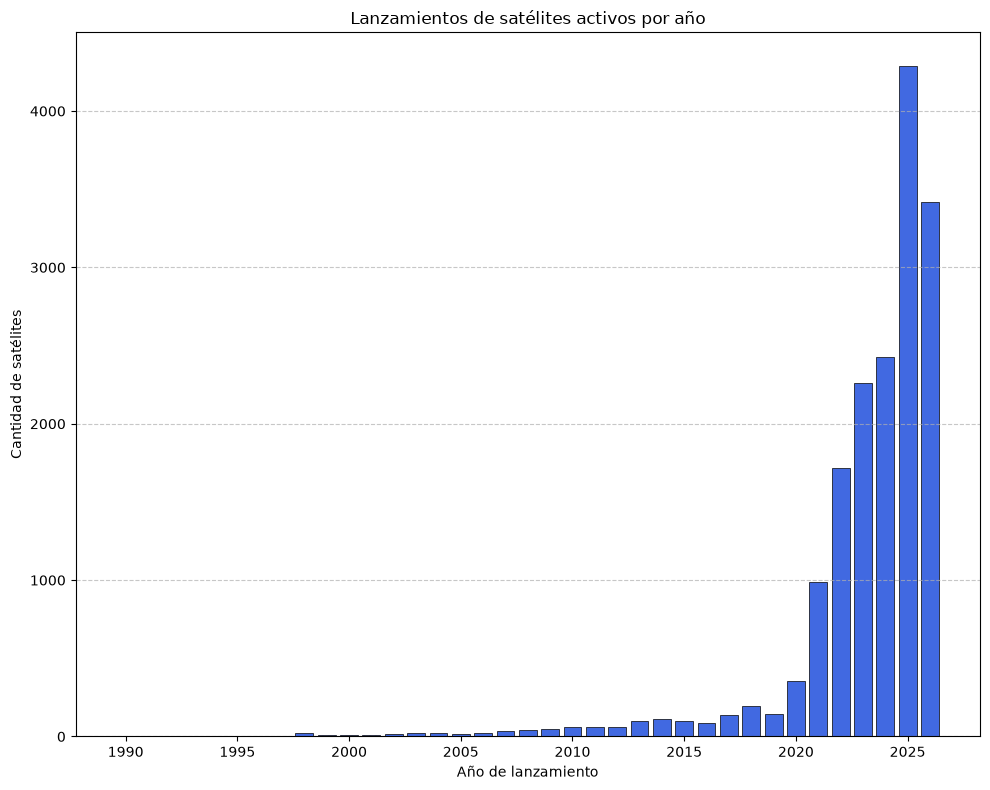

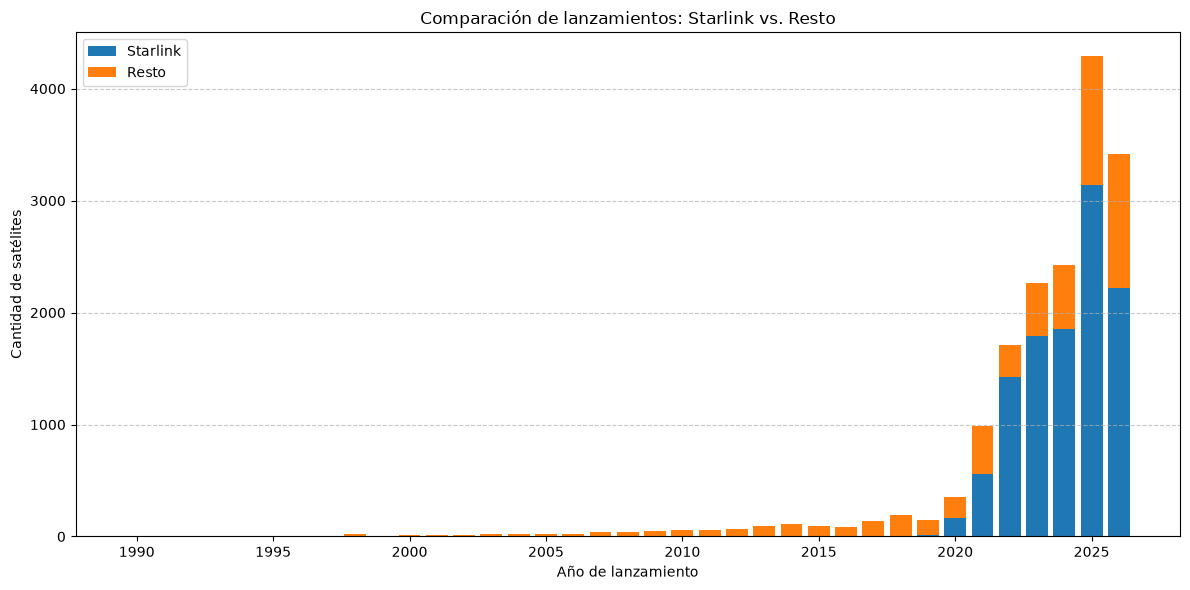

In [14]:
graficar_lanzamientos(lanzamientos_90_26)
graficar_lanzamientos_apilados(
    starlink_90_26,
    resto_90_26
)

**Análisis de lanzamientos (1990-2026)**

La escala de lanzamientos anuales cambió drásticamente a partir de **2020-2021**, cuando se supera por primera vez la barrera de los 350–900 satélites anuales hasta alcanzar picos superiores a los 4.000 en 2025

La mayor parte de este crecimiento exponencial se explica por el despliegue masivo de la constelación **Starlink**, que representa más de dos tercios del total de satélites activos lanzados en los últimos años

## 2. Altura media por grupo

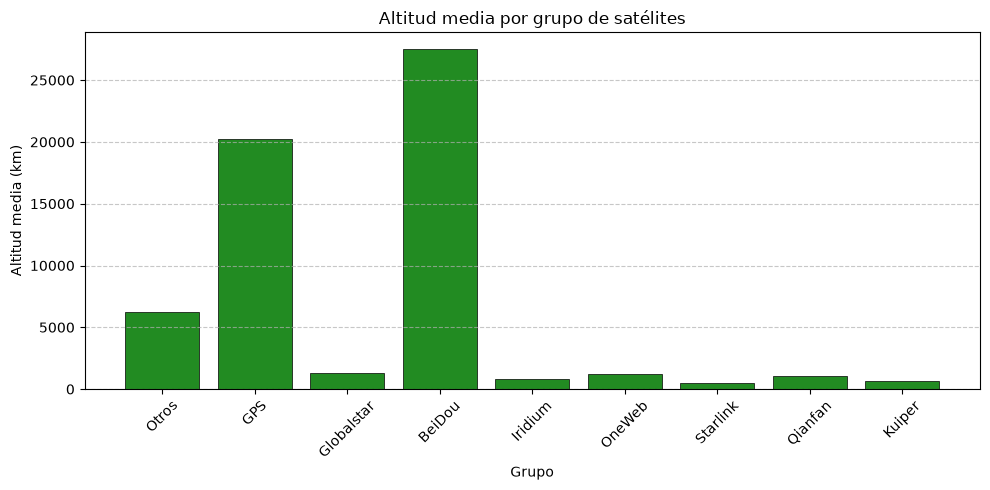

In [54]:
resumen = resumen_por_grupo(satelites)
graficar_altitud_media(resumen)

**Conclusión de la altitud**

Los grupos destinados a comunicaciones de baja latencia y observación terrestre (como **Starlink**, **OneWeb**, **Iridium** y **Planet**) operan en órbita terrestre baja (**LEO**, por debajo de los 2.000 km)

En contraste, los sistemas globales de navegación (**GPS**, **Galileo**, **GLONASS**, **BeiDou**) se ubican mucho más arriba en órbita media (**MEO**, alrededor de 20.000 km)

Mientras que los satélites geoestacionarios (**GEO**) alcanzan los ~35.786 km

# 3. Altitudes en órbita baja (LEO)

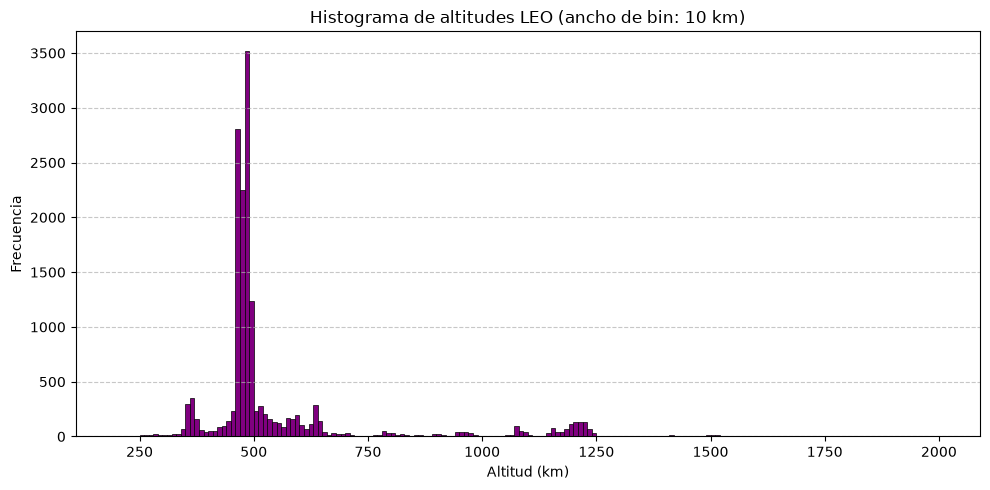

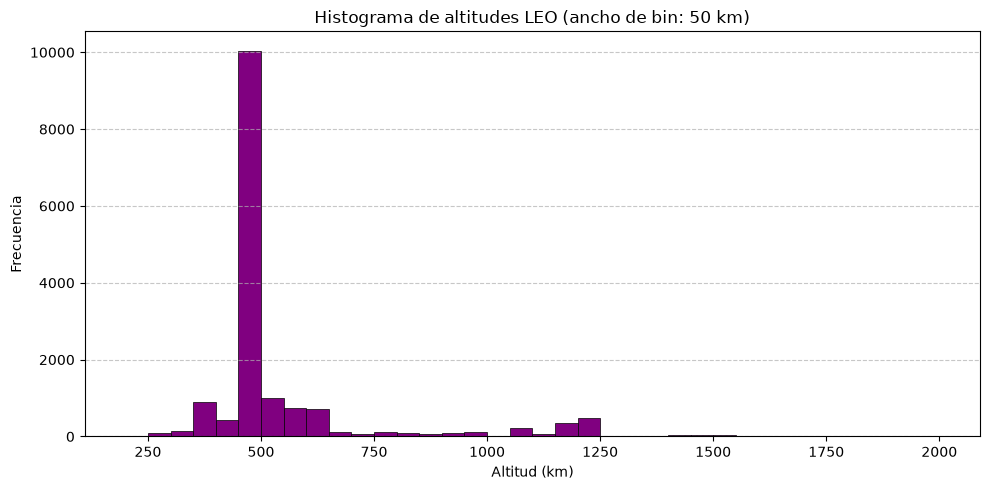

In [56]:
graficar_altitudes_leo(satelites, ancho_bin=10)
graficar_altitudes_leo(satelites, ancho_bin=50)

**Conclusión**

Con `ancho_bin=10` se distinguen sub-capas orbitales estrechas y picos bien definidos correspondientes a constelaciones específicas (como las distintas capas de Starlink entre **540 y 560 km** o OneWeb cerca de los **1.200 km**), y esos detalles quedan suavizados y/u ocultos al agrupar en intervalos más anchos con `ancho_bin=50`

La mayor concentración de satélites en órbita baja se encuentra en la franja de **500 a 600 km** de altitud